In [16]:
import pandas as pd
import matplotlib.pyplot as plt

In [17]:
files = [
    "../data/prices_round_1_day_-2.csv",
    "../data/prices_round_1_day_-1.csv",
    "../data/prices_round_1_day_0.csv",
]

datasets = {}

for file in files:
    df = pd.read_csv(file, sep=";")
    day = df["day"].iloc[0]
    datasets[day] = df


PRODUCT ASH_COATED_OSMIUM | DAY -2
count     9982.000000
mean      9998.169906
std          5.219914
min       9979.000000
25%       9994.500000
50%       9998.000000
75%      10002.000000
max      10019.000000
Name: mid_price, dtype: float64


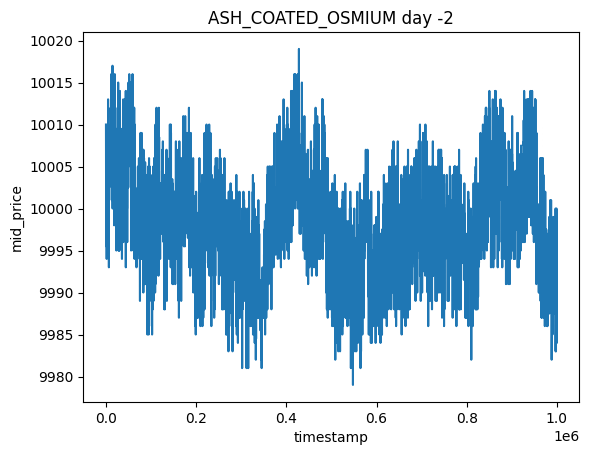


PRODUCT ASH_COATED_OSMIUM | DAY -1
count     9983.000000
mean     10000.833968
std          4.450045
min       9982.000000
25%       9998.000000
50%      10001.000000
75%      10003.000000
max      10019.000000
Name: mid_price, dtype: float64


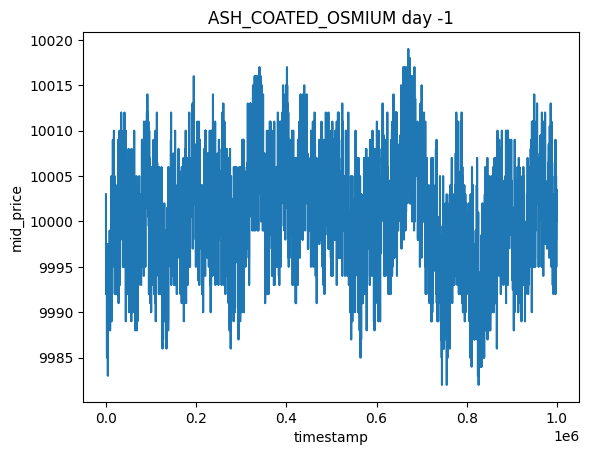


PRODUCT ASH_COATED_OSMIUM | DAY 0
count     9986.000000
mean     10001.608201
std          5.683730
min       9977.000000
25%       9998.000000
50%      10002.000000
75%      10005.000000
max      10023.000000
Name: mid_price, dtype: float64


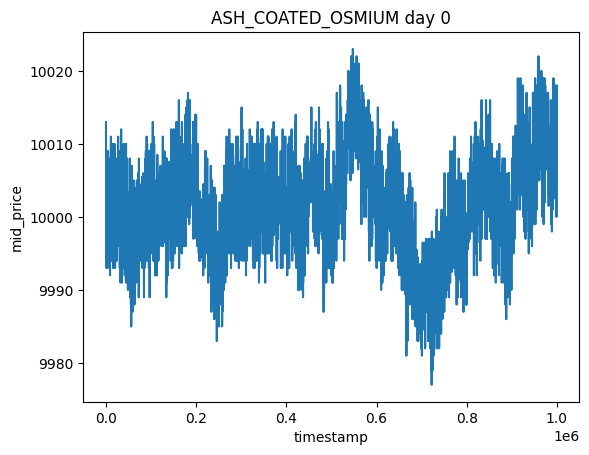

In [18]:
products = ["ASH_COATED_OSMIUM"]

for product in products:
    for day, df in datasets.items():
        df_p = df[df["product"] == product].copy()
        df_p = df_p[df_p["mid_price"] > 0]

        print(f"\nPRODUCT {product} | DAY {day}")
        print(df_p["mid_price"].describe())

        plt.figure()
        plt.plot(df_p["timestamp"], df_p["mid_price"])
        plt.title(f"{product} day {day}")
        plt.xlabel("timestamp")
        plt.ylabel("mid_price")
        plt.show()

In [21]:
import numpy as np

summary_rows = []

for product in products:
    for day, df in datasets.items():
        df_p = df[df["product"] == product].copy()
        df_p = df_p[df_p["mid_price"] > 0]
        df_p = df_p.sort_values(["timestamp"]).copy()

        fair_value = round(df_p["mid_price"].median())

        df_p["future_mid"] = df_p["mid_price"].shift(-1)
        df_p["future_change"] = df_p["future_mid"] - df_p["mid_price"]

        cheap = df_p["mid_price"] <= fair_value - 2
        expensive = df_p["mid_price"] >= fair_value + 2

        cheap_edge = df_p.loc[cheap, "future_change"].mean()
        expensive_edge = df_p.loc[expensive, "future_change"].mean()

        # 1) Tradability and execution-cost proxies from top-of-book fields.
        if {"bid_price_1", "ask_price_1"}.issubset(df_p.columns):
            spread = (df_p["ask_price_1"] - df_p["bid_price_1"]).astype(float)
            spread_mean = spread.mean()
            spread_p90 = spread.quantile(0.90)
            spread_nonzero_freq = (spread > 0).mean()
        else:
            spread_mean = np.nan
            spread_p90 = np.nan
            spread_nonzero_freq = np.nan

        if {"bid_volume_1", "ask_volume_1"}.issubset(df_p.columns):
            top_depth = (df_p["bid_volume_1"] + df_p["ask_volume_1"]).astype(float)
            top_depth_mean = top_depth.mean()
            top_depth_p10 = top_depth.quantile(0.10)
        else:
            top_depth_mean = np.nan
            top_depth_p10 = np.nan

        # Conservative round-trip crossing cost proxy in price units.
        roundtrip_cost_proxy = spread_mean

        cheap_edge_net = cheap_edge - roundtrip_cost_proxy if pd.notna(roundtrip_cost_proxy) else np.nan
        expensive_edge_net = (-expensive_edge) - roundtrip_cost_proxy if pd.notna(roundtrip_cost_proxy) else np.nan

        # 2) Signal quality / stability metrics.
        mid_change = df_p["mid_price"].diff()
        return_autocorr_lag1 = mid_change.autocorr(lag=1)

        cheap_count = int(cheap.sum())
        expensive_count = int(expensive.sum())
        cheap_hit_rate = (df_p.loc[cheap, "future_change"] > 0).mean() if cheap_count > 0 else np.nan
        expensive_hit_rate = (df_p.loc[expensive, "future_change"] < 0).mean() if expensive_count > 0 else np.nan

        deviation = (df_p["mid_price"] - fair_value).astype(float)
        x_t = deviation.iloc[:-1]
        x_next = deviation.iloc[1:]
        valid = x_t.notna() & x_next.notna()

        if valid.sum() >= 10:
            beta = np.polyfit(x_t[valid].to_numpy(), x_next[valid].to_numpy(), 1)[0]
        else:
            beta = np.nan

        if pd.notna(beta) and (0 < beta < 1):
            half_life = -np.log(2) / np.log(beta)
        else:
            half_life = np.nan

        summary_rows.append({
            "product": product,
            "day": day,
            "count": df_p["mid_price"].count(),
            "mean": df_p["mid_price"].mean(),
            "median": df_p["mid_price"].median(),
            "std": df_p["mid_price"].std(),
            "min": df_p["mid_price"].min(),
            "max": df_p["mid_price"].max(),
            "fair_value": fair_value,
            "cheap_freq": cheap.mean(),
            "expensive_freq": expensive.mean(),
            "cheap_edge": cheap_edge,
            "expensive_edge": expensive_edge,
            "spread_mean": spread_mean,
            "spread_p90": spread_p90,
            "spread_nonzero_freq": spread_nonzero_freq,
            "top_depth_mean": top_depth_mean,
            "top_depth_p10": top_depth_p10,
            "roundtrip_cost_proxy": roundtrip_cost_proxy,
            "cheap_edge_net": cheap_edge_net,
            "expensive_edge_net": expensive_edge_net,
            "return_autocorr_lag1": return_autocorr_lag1,
            "cheap_count": cheap_count,
            "expensive_count": expensive_count,
            "cheap_hit_rate": cheap_hit_rate,
            "expensive_hit_rate": expensive_hit_rate,
            "deviation_ar1_beta": beta,
            "half_life_steps": half_life,
        })

summary_df = pd.DataFrame(summary_rows).sort_values(["product", "day"])
summary_df

,product,day,count,mean,median,std,min,max,fair_value,cheap_freq,...,roundtrip_cost_proxy,cheap_edge_net,expensive_edge_net,return_autocorr_lag1,cheap_count,expensive_count,cheap_hit_rate,expensive_hit_rate,deviation_ar1_beta,half_life_steps
0,ASH_COATED_OSMIUM,-2,9982,9998.169906,9998.0,5.219914,9979.0,10019.0,9998,0.391605,...,16.149777,-15.044096,-15.038608,-0.500526,3909,3868,0.462267,0.448811,1.0,7.432518e+13
1,ASH_COATED_OSMIUM,-1,9983,10000.833968,10001.0,4.450045,9982.0,10019.0,10001,0.346689,...,16.191328,-14.906006,-14.793515,-0.498044,3461,3200,0.496677,0.501563,1.0,1.114878e+14
2,ASH_COATED_OSMIUM,0,9986,10001.608201,10002.0,5.683730,9977.0,10023.0,10002,0.372421,...,16.184467,-15.071668,-15.021867,-0.487252,3719,3362,0.465717,0.473825,1.0,8.671271e+13
